# 02. KOSPI200 선물 매매 규칙 + 유전 알고리즘 (2025-2 투자공학)

- 원본: 엑셀 `전략결과.xlsx` (Solver Evolutionary로 최적화). 여기서는 같은 수식을 Python으로 옮겨 **엑셀 값과 행 단위로 일치**하는지 먼저 확인한다.
- 지표: KOSPI 지수 OHLCV로 계산한 MFI(14), 볼린저밴드(20일, 2σ) 폭·%B. 매매 가격: 과제 시트의 Price 열.
- 원본은 전체 기간(2023-11-01~2025-04-30)으로 최적화하고 같은 기간으로 평가했다(인샘플).
  여기서는 기간을 나눠 **학습 구간에서 찾은 해가 검증 구간에서도 통하는지** 추가로 확인한다.

In [1]:
import sys, yaml
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib import font_manager
for f in ["AppleGothic", "Malgun Gothic", "NanumGothic", "Noto Sans CJK KR", "Noto Sans CJK JP", "Noto Serif CJK JP"]:  # CJK 글꼴은 한글 포함
    if any(f == x.name for x in font_manager.fontManager.ttflist):
        plt.rcParams["font.family"] = f; break
plt.rcParams["axes.unicode_minus"] = False
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
CFG = yaml.safe_load(open(ROOT / "configs/base.yaml"))
RES = ROOT / "results"; (RES / "figures").mkdir(parents=True, exist_ok=True)
from stock_selection import ga as GA
from stock_selection import metrics as M
G = CFG["ga"]
path = ROOT / G["data_file"]
assert path.exists(), "scripts/extract_ga_excel.py <전략결과.xlsx> 를 먼저 실행"
df = pd.read_csv(path, parse_dates=["date"])
print(df.date.min().date(), "~", df.date.max().date(), len(df), "거래일")

2023-11-01 ~ 2025-04-30 365 거래일


## 1. 엑셀 결과 재현

In [2]:
res = GA.simulate(df, GA.EXCEL_SOLUTION)
match = {c: bool(np.allclose(res[a], df[b])) for c, a, b in [("매매(R열)", "trade", "xl_trade"), ("손익(AE열)", "pnl", "xl_pnl"), ("수익률(AF열)", "return_rate", "xl_return_rate")]}
ev = GA.evaluate(df, GA.EXCEL_SOLUTION)
bh = df.price.iloc[-1] / df.price.iloc[0] - 1
print("엑셀과 행 단위 일치:", match)
print(f"수익(포인트) {ev['pnl']:.2f} | 필요 현금 {ev['needed_cash']:.2f} | 수익률 {ev['return_rate']:.2%} | 매수 {ev['n_buys']}회 매도 {ev['n_sells']}회 | 최대 보유 {ev['max_position']:.0f}")
print(f"같은 기간 단순 보유(Price): {bh:+.2%}")

엑셀과 행 단위 일치: {'매매(R열)': True, '손익(AE열)': True, '수익률(AF열)': True}
수익(포인트) 533.31 | 필요 현금 1686.04 | 수익률 31.63% | 매수 18회 매도 18회 | 최대 보유 1
같은 기간 단순 보유(Price): +7.68%


## 2. 같은 GA를 전체 기간에 다시 돌리면 (인샘플)

In [3]:
full = {}
for s in G["seeds"]:
    p, f, hist = GA.optimize(df, pop=G["population"], gens=G["generations"], seed=s)
    full[s] = (p, f, hist)
pd.Series({f"seed {s}": v[1] for s, v in full.items()} | {"엑셀 Solver 해": ev["return_rate"]}).to_frame("전체 기간 수익률").style.format("{:+.2%}")

,전체 기간 수익률
seed 0,+44.35%
seed 1,+43.98%
seed 2,+47.90%
seed 3,+53.81%
seed 4,+54.97%
엑셀 Solver 해,+31.63%


## 3. 학습/검증 분리 (워크포워드 1회)

In [4]:
cut = pd.Timestamp(G["train_end"])
tr, te = df[df.date <= cut].reset_index(drop=True), df[df.date > cut].reset_index(drop=True)
print(f"학습 {tr.date.min().date()}~{tr.date.max().date()} ({len(tr)}일) | 검증 {te.date.min().date()}~{te.date.max().date()} ({len(te)}일)")
rows, params = [], {"엑셀 Solver 해(전체 기간 최적화)": GA.EXCEL_SOLUTION}
for s in G["seeds"]:
    p, f_tr, _ = GA.optimize(tr, pop=G["population"], gens=G["generations"], seed=s)
    e_te = GA.evaluate(te, p)
    params[f"seed {s}(학습 구간 최적화)"] = p
    rows.append({"해": f"seed {s}", "학습 수익률": f_tr, "검증 수익률": e_te["return_rate"], "검증 매수 횟수": e_te["n_buys"]})
x_tr, x_te = GA.evaluate(tr, GA.EXCEL_SOLUTION), GA.evaluate(te, GA.EXCEL_SOLUTION)
rows.append({"해": "엑셀 Solver 해", "학습 수익률": x_tr["return_rate"], "검증 수익률": x_te["return_rate"], "검증 매수 횟수": x_te["n_buys"]})
rows.append({"해": "단순 보유", "학습 수익률": tr.price.iloc[-1] / tr.price.iloc[0] - 1, "검증 수익률": te.price.iloc[-1] / te.price.iloc[0] - 1, "검증 매수 횟수": 1})
wf = pd.DataFrame(rows).set_index("해")
wf.to_csv(RES / "ga_walkforward.csv"); GA.params_table(params).to_csv(RES / "ga_params.csv")
display(wf.style.format({"학습 수익률": "{:+.2%}", "검증 수익률": "{:+.2%}"}), GA.params_table(params).round(3))

학습 2023-11-01~2024-10-31 (244일) | 검증 2024-11-01~2025-04-30 (121일)


,학습 수익률,검증 수익률,검증 매수 횟수
해,,,
seed 0,+29.92%,+11.90%,3
seed 1,+42.54%,+3.24%,5
seed 2,+32.67%,+7.59%,4
seed 3,+23.85%,+3.94%,4
seed 4,+47.14%,-1.19%,7
엑셀 Solver 해,+22.53%,+8.95%,4
단순 보유,+8.15%,+0.35%,1


,엑셀 Solver 해(전체 기간 최적화),seed 0(학습 구간 최적화),seed 1(학습 구간 최적화),seed 2(학습 구간 최적화),seed 3(학습 구간 최적화),seed 4(학습 구간 최적화)
mfi_lo,32.360,82.441,79.474,88.293,84.213,29.471
mfi_hi,50.066,63.324,71.982,64.521,61.217,66.198
bbw_lo,0.117,0.138,0.081,0.139,0.023,0.124
pctb_lo,0.216,0.155,0.372,0.152,-0.200,0.081
first_buy,1.000,11.000,12.000,10.000,11.000,20.000
after_buy,0.000,0.000,0.000,0.000,0.000,0.000
first_sell,1.000,1.000,11.000,9.000,1.000,17.000
after_sell,1.000,10.000,9.000,5.000,10.000,1.000
K,2.000,5.000,2.000,4.000,3.000,1.000
N,3.000,2.000,2.000,2.000,3.000,3.000


## 4. 성과표

In [5]:
def ga_col(e, label_days):
    s = M.summary(e["daily_returns"].iloc[1:].reset_index(drop=True), G["periods_per_year"], min_periods_for_annualized=252,
                  n_trades=e["n_buys"] + e["n_sells"])
    s["수익률(엑셀 정의: 손익/필요현금)"] = e["return_rate"]
    s["평가 기간"] = label_days
    return s
best_seed = wf.drop(index=["엑셀 Solver 해", "단순 보유"])["학습 수익률"].idxmax()
p_best = params[f"{best_seed}(학습 구간 최적화)"]
span = lambda d: f"{d.date.min().date()} ~ {d.date.max().date()}"
tbl = {"엑셀 해 · 전체(인샘플)": ga_col(ev, span(df)),
       f"학습 최적해({best_seed}) · 검증(아웃샘플)": ga_col(GA.evaluate(te, p_best), span(te)),
       "엑셀 해 · 검증 구간": ga_col(x_te, span(te))}
md_t = M.to_markdown(tbl)
(RES / "ga_summary.md").write_text(md_t + "\n"); print(md_t)

| 지표 | 엑셀 해 · 전체(인샘플) | 학습 최적해(seed 4) · 검증(아웃샘플) | 엑셀 해 · 검증 구간 |
|---|---|---|---|
| 기간 수 | 364 | 120 | 120 |
| 누적수익률 | +31.63% | -1.19% | +8.95% |
| 연환산수익률 | +20.96% | — | — |
| 연환산변동성 | 10.21% | 11.38% | 12.88% |
| 샤프 | 1.91 | -0.16 | 1.46 |
| MDD | -4.77% | -6.59% | -5.72% |
| 칼마 | 4.40 | — | — |
| 승률 | 16.48% | 42.50% | 19.17% |
| 거래 횟수 | 36 | 26 | 8 |
| 수익률(엑셀 정의: 손익/필요현금) | +31.63% | -1.19% | +8.95% |
| 평가 기간 | 2023-11-01 ~ 2025-04-30 | 2024-11-01 ~ 2025-04-30 | 2024-11-01 ~ 2025-04-30 |


## 5. 그림

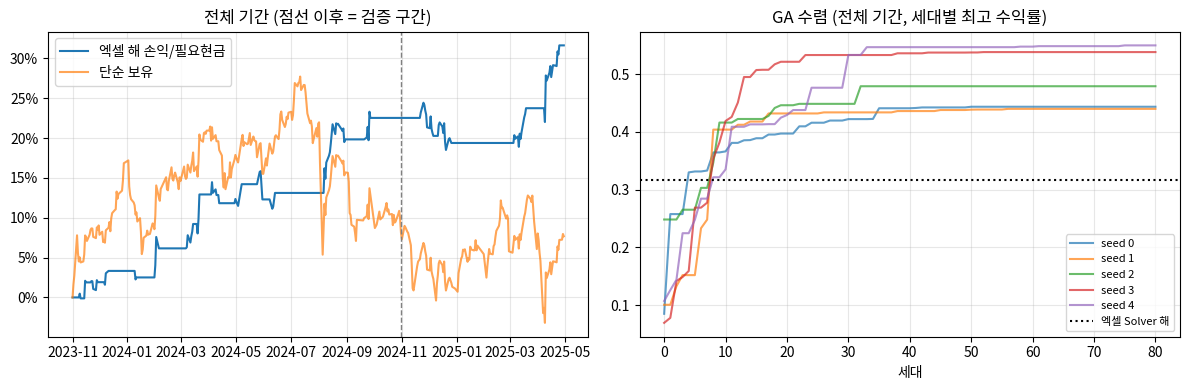

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
cap = ev["needed_cash"]
axes[0].plot(df.date, ev["result"]["pnl"] / cap, label="엑셀 해 손익/필요현금")
axes[0].plot(df.date, df.price / df.price.iloc[0] - 1, label="단순 보유", alpha=.7)
axes[0].axvline(cut, color="gray", ls="--", lw=1); axes[0].set_title("전체 기간 (점선 이후 = 검증 구간)")
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}")); axes[0].legend(); axes[0].grid(alpha=.3)
for s, (p, f, hist) in full.items():
    axes[1].plot(hist, alpha=.7, label=f"seed {s}")
axes[1].axhline(ev["return_rate"], color="k", ls=":", label="엑셀 Solver 해")
axes[1].set_title("GA 수렴 (전체 기간, 세대별 최고 수익률)"); axes[1].set_xlabel("세대"); axes[1].legend(fontsize=8); axes[1].grid(alpha=.3)
plt.tight_layout(); plt.savefig(RES / "figures/ga_overview.png", dpi=150); plt.show()